<a href="https://colab.research.google.com/github/madotfx/karhutla/blob/main/karhutla.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###Persiapan Environment & Instalasi Library



In [ ]:
!pip install -q transformers datasets accelerate scikit-learn pandas torch

In [ ]:
import pandas as pd
import numpy as np
import torch
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from torch.optim import AdamW

### 1. Load Dataset

In [ ]:
from google.colab import files
import pandas as pd

# Baris ini akan memunculkan tombol "Choose Files" di Colab Anda
uploaded = files.upload()

# Mengambil nama file yang baru saja diunggah secara otomatis
filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

print(f"Berhasil memuat file: {filename}")
print(df.head())

Saving kebakaran hutan.csv to kebakaran hutan (1).csv
Berhasil memuat file: kebakaran hutan (1).csv
                    id                                         url  \
0  2108384969894842817      /ejaaipongg/status/2108384969894842817   
1  2113667656377327880      /rsugarcoat/status/2113667656377327880   
2  2114567369859399723       /urflowerz/status/2114567369859399723   
3  2115437559551832279  /gracularobusta/status/2115437559551832279   
4  2112547900077269214   /ganjarpranowo/status/2112547900077269214   

                         ts                                               text  
0  2026-10-09T02:32:03.000Z  JANGAN LELAH UNTUK MENGABARKAN SITUSIASI KALIM...  
1  2026-10-23T16:23:33.000Z  pembahasan aijing jadi trending topik di indo ...  
2  2026-10-26T03:58:42.000Z  UP!! LANGIT PALANGKARAYA BUKAN KUNING LAGI TAP...  
3  2026-10-28T13:36:31.000Z  1. Polisi waktu memadamkan api Karhutla. 2. Po...  
4  2026-10-20T14:14:03.000Z  1. Umumkan Karhutla sebagai bencana nasional.

In [ ]:
# Bersihkan data dari missing value pada kolom text
df = df.dropna(subset=['text']).reset_index(drop=True)

# Simulasi Label (Ganti dengan kolom label asli Anda jika sudah ada)
np.random.seed(42)
df['label'] = np.random.choice([0, 1, 2], size=len(df))
print(f"Total baris data yang digunakan: {len(df)}")
print(df['label'].value_counts())

Total baris data yang digunakan: 986
label
0    352
1    319
2    315
Name: count, dtype: int64


### 2. Split Data (Train, Validation, Test)

In [ ]:
train_texts, temp_texts, train_labels, temp_labels = train_test_split(
    df['text'].values, df['label'].values, test_size=0.2, random_state=42, stratify=df['label'].values
)
val_texts, test_texts, val_labels, test_labels = train_test_split(
    temp_texts, temp_labels, test_size=0.5, random_state=42, stratify=temp_labels
)

### 3. Inisialisasi Tokenizer IndoBERT

In [ ]:
MODEL_NAME = "indobenchmark/indobert-base-p1"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class KarhutlaDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, item):
        text = str(self.texts[item])
        label = self.labels[item]

        encoding = self.tokenizer(
            text,
            add_special_tokens=True,
            max_length=self.max_len,
            padding='max_length',
            truncation=True,
            return_attention_mask=True,
            return_tensors='pt',
        )

        return {
            'input_ids': encoding['input_ids'].flatten(),
            'attention_mask': encoding['attention_mask'].flatten(),
            'labels': torch.tensor(label, dtype=torch.long)
        }

MAX_LEN = 128
BATCH_SIZE = 16

train_dataset = KarhutlaDataset(train_texts, train_labels, tokenizer, MAX_LEN)
val_dataset = KarhutlaDataset(val_texts, val_labels, tokenizer, MAX_LEN)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE)

### 4. Load Model IndoBERT untuk Klasifikasi

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
num_classes = len(np.unique(df['label']))

model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=num_classes)
model.to(device)

[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.bias   | MISSING | 
classifier.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(50000, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12,

### 5. Konfigurasi Optimizer & Scheduler

In [ ]:
EPOCHS = 3
optimizer = AdamW(model.parameters(), lr=2e-5)
total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=0, num_training_steps=total_steps)

### 6. Training Loop

In [ ]:
for epoch in range(EPOCHS):
    print(f"\n--- Epoch {epoch + 1}/{EPOCHS} ---")
    model.train()
    total_train_loss = 0

    for batch in train_loader:
        optimizer.zero_grad()

        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
        loss = outputs.loss
        total_train_loss += loss.item()

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()

    avg_train_loss = total_train_loss / len(train_loader)
    print(f"Rata-rata Training Loss: {avg_train_loss:.4f}")

    # Validasi per Epoch
    model.eval()
    val_preds, val_trues = [], []
    with torch.no_grad():
        for batch in val_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)

            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            preds = torch.argmax(outputs.logits, dim=1)

            val_preds.extend(preds.cpu().numpy())
            val_trues.extend(labels.cpu().numpy())

    val_acc = accuracy_score(val_trues, val_preds)
    print(f"Validasi Akurasi: {val_acc:.4f}")


--- Epoch 1/3 ---
Rata-rata Training Loss: 1.1220
Validasi Akurasi: 0.3333

--- Epoch 2/3 ---
Rata-rata Training Loss: 1.0923
Validasi Akurasi: 0.3535

--- Epoch 3/3 ---
Rata-rata Training Loss: 1.0309
Validasi Akurasi: 0.3535


### 7. Evaluasi Akhir pada Test Set

In [ ]:
test_dataset = KarhutlaDataset(test_texts, test_labels, tokenizer, MAX_LEN)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE)

model.eval()
test_preds, test_trues = [], []
with torch.no_grad():
    for batch in test_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        preds = torch.argmax(outputs.logits, dim=1)

        test_preds.extend(preds.cpu().numpy())
        test_trues.extend(labels.cpu().numpy())

print("\n--- Laporan Evaluasi Pengujian (Test Set) ---")
print(classification_report(test_trues, test_preds))


--- Laporan Evaluasi Pengujian (Test Set) ---
              precision    recall  f1-score   support

           0       0.28      0.47      0.35        36
           1       0.15      0.12      0.14        32
           2       0.42      0.16      0.23        31

    accuracy                           0.26        99
   macro avg       0.28      0.25      0.24        99
weighted avg       0.28      0.26      0.25        99



### Pelabelan Otomatis Menggunakan Kamus (Lexicon-Based Labeling)

Karena Akurasi masih rendah

In [ ]:
# Definisikan kamus kata kunci sederhana (bisa diperluas)
kata_negatif = ['asap', 'sesak', 'parah', 'krisis', 'mati', 'bencana', 'marah', 'kecewa', 'lambat', 'rugi', 'abu', 'korban']
kata_positif = ['bantu', 'padam', 'aman', 'teratasi', 'siap', 'terima kasih', 'sukses', 'cepat']

def labeling_sentimen(text):
    text_lower = str(text).lower()

    # Hitung kemunculan kata kunci
    neg_count = sum(1 for word in kata_negatif if word in text_lower)
    pos_count = sum(1 for word in kata_positif if word in text_lower)

    # Tentukan label: 0 = Negatif/Kritik, 1 = Netral, 2 = Positif
    if neg_count > pos_count:
        return 0
    elif pos_count > neg_count:
        return 2
    else:
        return 1

# Terapkan fungsi ke kolom text
df['label'] = df['text'].apply(labeling_sentimen)

# Cek distribusi label baru
print(df['label'].value_counts())

# Simpan ke file CSV baru agar bisa digunakan permanen
df.to_csv('kebakaran_hutan_labeled.csv', index=False)

label
1    556
0    281
2    149
Name: count, dtype: int64


In [ ]:
import re

###Pelabelan Otomatis Menggunakan Kamus (Lexicon-Based Labeling)

In [ ]:
# Pastikan tidak ada data kosong pada kolom text
df = df.dropna(subset=['text']).reset_index(drop=True)

# 2. Hapus Data Duplikat & Spam (Retweet identik atau pesan berulang)
# Menggunakan kolom 'text' untuk mendeteksi duplikasi
df = df.drop_duplicates(subset=['text']).reset_index(drop=True)
print(f"Jumlah data setelah duplikat/spam dihapus: {len(df)}")

# 3. Kamus Normalisasi Slang / Bahasa Gaul / Singkatan Media Sosial
# Menambahkan kata-kata gaul lain yang sering muncul di dataset
slang_dict = {
    'tdk': 'tidak',
    'tundak': 'tidak',
    'nggk': 'tidak',
    'nggak': 'tidak',
    'gak': 'tidak',
    'g': 'tidak',
    'bgt': 'banget',
    'bgd': 'banget',
    'krn': 'karena',
    'karna': 'karena',
    'utk': 'untuk',
    'btk': 'bentuk',
    'dlm': 'dalam',
    'dgn': 'dengan',
    'jg': 'juga',
    'aja': 'saja',
    'aj': 'saja',
    'bener': 'benar',
    'beneran': 'benaran',
    'tp': 'tapi',
    'hrs': 'harus',
    'sdh': 'sudah',
    'blm': 'belum',
    'pd': 'pada',
    'msh': 'masih',
    'org': 'orang',
    'mrk': 'mereka',
    'kalo': 'kalau',
    'klu': 'kalau',
    'nyari': 'mencari',
    'tau': 'tahu',
    'bencanaa': 'bencana',
    'asapp': 'asap'
}

def advanced_cleaning(text):
    if not isinstance(text, str):
        return ""

    # Ubah ke huruf kecil (lowercase)
    text = text.lower()

    # Hapus tautan URL (http/https/www)
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)

    # Hapus mention Twitter (@username)
    text = re.sub(r'@[\w_]+', '', text)

    # Hapus hashtag (#) tapi sisakan teksnya (opsional, di sini kita hapus tanda # nya)
    text = re.sub(r'#', '', text)

    # Hapus emoji atau simbol non-alfanumerik khusus (bisa disesuaikan)
    # Baris ini membersihkan karakter selain huruf, angka, dan spasi dasar
    text = re.sub(r'[^\w\s]', ' ', text)

    # Normalisasi huruf berulang yang berlebihan (contoh: "bencanaaa" -> "bencana", "panaaas" -> "panas")
    text = re.sub(r'(.)\1{2,}', r'\1', text)

    # Pecah kata untuk melakukan normalisasi slang
    words = text.split()
    normalized_words = [slang_dict.get(word, word) for word in words]
    text = ' '.join(normalized_words)

    # Hapus spasi berlebih
    text = re.sub(r'\s+', ' ', text).strip()

    return text

# 4. Terapkan fungsi pembersihan ke kolom text
df['cleaned_text'] = df['text'].apply(advanced_cleaning)

# Hapus baris jika setelah dibersihkan teksnya menjadi kosong (misal isinya cuma link/mention doang)
df = df[df['cleaned_text'].str.len() > 0].reset_index(drop=True)

print(f"Jumlah data akhir siap training: {len(df)}")

# Tampilkan contoh hasil perbandingan sebelum dan sesudah dibersihkan
print("\n--- Contoh Perbandingan Teks ---")
for i in range(min(3, len(df))):
    print(f"Asli   : {df.loc[i, 'text']}")
    print(f"Bersih : {df.loc[i, 'cleaned_text']}")
    print("-" * 40)

# Simpan ke file CSV baru
df.to_csv('kebakaran_hutan_preprocessed.csv', index=False)

Jumlah data setelah duplikat/spam dihapus: 986
Jumlah data akhir siap training: 986

--- Contoh Perbandingan Teks ---
Asli   : JANGAN LELAH UNTUK MENGABARKAN SITUSIASI KALIMANTAN Berbulan-bulan situasi di Kalimantan belum pulih dari Karhutla, rakyat kalimantan dipaksa menghirup asap tidak sehat setiap hari, jalanan penuh dengan abu. kami krisis air bersih dan ngalamin mati listrik ber jam jam.
Bersih : jangan lelah untuk mengabarkan situsiasi kalimantan berbulan bulan situasi di kalimantan belum pulih dari karhutla rakyat kalimantan dipaksa menghirup asap tidak sehat setiap hari jalanan penuh dengan abu kami krisis air bersih dan ngalamin mati listrik ber jam jam
----------------------------------------
Asli   : pembahasan aijing jadi trending topik di indo dan netizen auto lupa karhutla kalimantan, sumatera, ama papua. ini permainan buzzerp
Bersih : pembahasan aijing jadi trending topik di indo dan netizen auto lupa karhutla kalimantan sumatera ama papua ini permainan buzzerp
--------

In [ ]:
# Definisikan kamus kata kunci sederhana (bisa diperluas)
kata_negatif = ['asap', 'sesak', 'parah', 'krisis', 'mati', 'bencana', 'marah', 'kecewa', 'lambat', 'rugi', 'abu', 'korban']
kata_positif = ['bantu', 'padam', 'aman', 'teratasi', 'siap', 'terima kasih', 'sukses', 'cepat']

def labeling_sentimen(text):
    text_lower = str(text).lower()

    # Hitung kemunculan kata kunci
    neg_count = sum(1 for word in kata_negatif if word in text_lower)
    pos_count = sum(1 for word in kata_positif if word in text_lower)

    # Tentukan label: 0 = Negatif/Kritik, 1 = Netral, 2 = Positif
    if neg_count > pos_count:
        return 0
    elif pos_count > neg_count:
        return 2
    else:
        return 1

# Terapkan fungsi ke kolom text
df['label'] = df['text'].apply(labeling_sentimen)

# Cek distribusi label baru
print(df['label'].value_counts())

# Simpan ke file CSV baru agar bisa digunakan permanen
df.to_csv('kebakaran_hutan_labeled.csv', index=False)

label
1    556
0    281
2    149
Name: count, dtype: int64


### Tangani Kelas yang Tidak Seimbang (Class Imbalance)

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

In [ ]:
# Hitung bobot kelas secara otomatis dari data
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(df['label'].values),
    y=df['label'].values
)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float).to(device)

# Masukkan ke CrossEntropyLoss saat training
loss_fn = torch.nn.CrossEntropyLoss(weight=class_weights_tensor)

In [ ]:
# Load data final yang sudah bersih dan berlabel
df = pd.read_csv('kebakaran_hutan_preprocessed.csv')

# Pastikan menggunakan kolom 'cleaned_text' sebagai input teks
train_texts, temp_texts, train_labels, temp_labels = train_test_split(
    df['cleaned_text'].values, df['label'].values, test_size=0.2, random_state=42, stratify=df['label'].values
)

In [ ]:
# Pastikan tidak ada missing value pada cleaned_text
df = df.dropna(subset=['cleaned_text']).reset_index(drop=True)

print(f"Total data siap training: {len(df)}")
print("Distribusi Label:")
print(df['label'].value_counts())

Total data siap training: 986
Distribusi Label:
label
1    556
0    281
2    149
Name: count, dtype: int64


In [ ]:
# 2. Split Data (Train, Validation, Test dengan Stratify agar proporsi kelas seimbang)
train_texts, temp_texts, train_labels, temp_labels = train_test_split(
    df['cleaned_text'].values, df['label'].values, test_size=0.2, random_state=42, stratify=df['label'].values
)
val_texts, test_texts, val_labels, test_labels = train_test_split(
    temp_texts, temp_labels, test_size=0.5, random_state=42, stratify=temp_labels
)

In [ ]:
# 3. Inisialisasi Tokenizer IndoBERT
MODEL_NAME = "indobenchmark/indobert-base-p1"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

class KarhutlaDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, item):
        text = str(self.texts[item])
        label = self.labels[item]

        # Tokenisasi langsung menggunakan tokenizer
        encoding = self.tokenizer(
            text,
            add_special_tokens=True,
            max_length=self.max_len,
            padding='max_length',
            truncation=True,
            return_attention_mask=True,
            return_tensors='pt',
        )

        return {
            'input_ids': encoding['input_ids'].flatten(),
            'attention_mask': encoding['attention_mask'].flatten(),
            'labels': torch.tensor(label, dtype=torch.long)
        }

# Gunakan MAX_LEN 160 agar kalimat agak panjang tidak terpotong
MAX_LEN = 160
BATCH_SIZE = 16

train_dataset = KarhutlaDataset(train_texts, train_labels, tokenizer, MAX_LEN)
val_dataset = KarhutlaDataset(val_texts, val_labels, tokenizer, MAX_LEN)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE)

In [ ]:
# 4. Load Model IndoBERT untuk Klasifikasi
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
num_classes = len(np.unique(df['label']))

model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=num_classes)
model.to(device)

[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.bias   | MISSING | 
classifier.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(50000, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12,

In [ ]:
# 5. Tangani Imbalanced Data Menggunakan Class Weights pada Loss Function
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_labels),
    y=train_labels
)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float).to(device)
loss_fn = torch.nn.CrossEntropyLoss(weight=class_weights_tensor)

In [ ]:
# 6. Konfigurasi Optimizer & Scheduler (Naikkan Epoch menjadi 4 untuk hasil optimal)
EPOCHS = 4
optimizer = AdamW(model.parameters(), lr=2e-5)
total_steps = len(train_loader) * EPOCHS
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=0,
    num_training_steps=total_steps
)

In [ ]:
# 7. Training Loop dengan Penanganan Loss Berbobot
for epoch in range(EPOCHS):
    print(f"\n--- Epoch {epoch + 1}/{EPOCHS} ---")
    model.train()
    total_train_loss = 0

    for batch in train_loader:
        optimizer.zero_grad()

        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        outputs = model(input_ids=input_ids, attention_mask=attention_mask)

        # Hitung loss menggunakan bobot kelas
        loss = loss_fn(outputs.logits, labels)
        total_train_loss += loss.item()

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()

    avg_train_loss = total_train_loss / len(train_loader)
    print(f"Rata-rata Training Loss: {avg_train_loss:.4f}")

    # Validasi per Epoch
    model.eval()
    val_preds, val_trues = [], []
    with torch.no_grad():
        for batch in val_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)

            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            preds = torch.argmax(outputs.logits, dim=1)

            val_preds.extend(preds.cpu().numpy())
            val_trues.extend(labels.cpu().numpy())

    val_acc = accuracy_score(val_trues, val_preds)
    print(f"Validasi Akurasi: {val_acc:.4f}")


--- Epoch 1/4 ---
Rata-rata Training Loss: 1.0322
Validasi Akurasi: 0.6465

--- Epoch 2/4 ---
Rata-rata Training Loss: 0.6067
Validasi Akurasi: 0.8485

--- Epoch 3/4 ---
Rata-rata Training Loss: 0.3406
Validasi Akurasi: 0.7980

--- Epoch 4/4 ---
Rata-rata Training Loss: 0.2110
Validasi Akurasi: 0.8283


#

In [ ]:
test_dataset = KarhutlaDataset(test_texts, test_labels, tokenizer, MAX_LEN)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE)

model.eval()
test_preds, test_trues = [], []
with torch.no_grad():
    for batch in test_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        preds = torch.argmax(outputs.logits, dim=1)

        test_preds.extend(preds.cpu().numpy())
        test_trues.extend(labels.cpu().numpy())

print("\n--- Laporan Evaluasi Pengujian Akhir (Test Set) ---")
print(classification_report(test_trues, test_preds))


--- Laporan Evaluasi Pengujian Akhir (Test Set) ---
              precision    recall  f1-score   support

           0       0.85      0.79      0.81        28
           1       0.82      0.82      0.82        56
           2       0.53      0.60      0.56        15

    accuracy                           0.78        99
   macro avg       0.73      0.74      0.73        99
weighted avg       0.78      0.78      0.78        99



###Download Model Fine Tuning IndoBERT ke collab dan Lokal

In [ ]:
import os

# Tentukan nama folder tempat penyimpanan model
model_save_path = 'model_indobert_karhutla'

# Simpan model dan tokenizer
model.save_pretrained(model_save_path)
tokenizer.save_pretrained(model_save_path)

print(f"Model dan Tokenizer berhasil disimpan di folder: '{model_save_path}'")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model dan Tokenizer berhasil disimpan di folder: 'model_indobert_karhutla'


In [ ]:
import shutil

# Kompres folder model menjadi file ZIP
shutil.make_archive('model_indobert_karhutla', 'zip', model_save_path)

# Unduh file ZIP secara otomatis ke komputer lokal Anda
from google.colab import files
files.download('model_indobert_karhutla.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

###Confusion Matrix

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

In [ ]:
# 1. Buat Confusion Matrix dari data uji (test set) aktual dan prediksi model sebelumnya
cm = confusion_matrix(test_trues, test_preds)

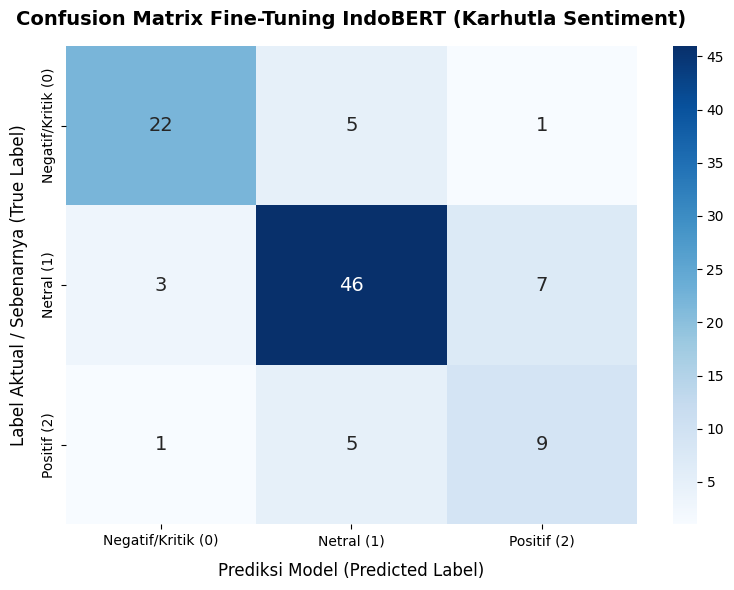

In [ ]:
# 2. Definisikan label kelas
class_names = ['Negatif/Kritik (0)', 'Netral (1)', 'Positif (2)']

# 3. Plotting Confusion Matrix dalam satu blok utuh
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names,
            cbar=True, annot_kws={"size": 14})

# 4. Kustomisasi Judul dan Label
plt.title('Confusion Matrix Fine-Tuning IndoBERT (Karhutla Sentiment)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Prediksi Model (Predicted Label)', fontsize=12, labelpad=10)
plt.ylabel('Label Aktual / Sebenarnya (True Label)', fontsize=12, labelpad=10)

# 5. Tampilkan dan simpan gambar
plt.tight_layout()
plt.savefig('confusion_matrix_indoBERT.png', dpi=300)
plt.show()

### Membandingkan Train dengan Algoritma SVM

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# 1. Load Dataset yang sudah bersih dan berlabel
df = pd.read_csv('kebakaran_hutan_preprocessed.csv')

# Pastikan kolom label sudah ada (dari proses pelabelan sebelumnya)
# Jika belum ada kolom label, jalankan ulang fungsi pelabelan atau pastikan file CSV memuat kolom 'label'
if 'label' not in df.columns:
    # Pelabelan otomatis cepat jika kolom label belum terbawa
    kata_negatif = ['asap', 'sesak', 'parah', 'krisis', 'mati', 'bencana', 'marah', 'kecewa', 'lambat', 'rugi', 'abu', 'korban']
    kata_positif = ['bantu', 'padam', 'aman', 'teratasi', 'siap', 'terima kasih', 'sukses', 'cepat']
    def quick_label(text):
        t = str(text).lower()
        neg = sum(1 for w in kata_negatif if w in t)
        pos = sum(1 for w in kata_positif if w in t)
        if neg > pos: return 0
        elif pos > neg: return 2
        else: return 1
    df['label'] = df['cleaned_text'].apply(quick_label)

In [ ]:
# 2. Split Data dengan proporsi yang sama persis seperti IndoBERT (Train/Val/Test)
X_text = df['cleaned_text'].values
y = df['label'].values

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X_text, y, test_size=0.10, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.1111, random_state=42, stratify=y_train_val
)

In [ ]:
# 3. Ekstraksi Fitur Menggunakan TF-IDF Vectorizer
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

In [ ]:
# 4. Inisialisasi dan Latih Model SVM (Gunakan class_weight='balanced' untuk imbalanced data)
svm_model = SVC(kernel='linear', C=1.0, class_weight='balanced', random_state=42)
svm_model.fit(X_train_tfidf, y_train)
# 5. Prediksi pada Test Set
y_pred = svm_model.predict(X_test_tfidf)
# 6. Evaluasi Performa
acc = accuracy_score(y_test, y_pred)
print(f"Akurasi Model SVM (TF-IDF): {acc:.4f}\n")
print("--- Laporan Klasifikasi SVM ---")
print(classification_report(y_test, y_pred))

Akurasi Model SVM (TF-IDF): 0.7778

--- Laporan Klasifikasi SVM ---
              precision    recall  f1-score   support

           0       0.90      0.64      0.75        28
           1       0.77      0.95      0.85        56
           2       0.60      0.40      0.48        15

    accuracy                           0.78        99
   macro avg       0.76      0.66      0.69        99
weighted avg       0.78      0.78      0.76        99



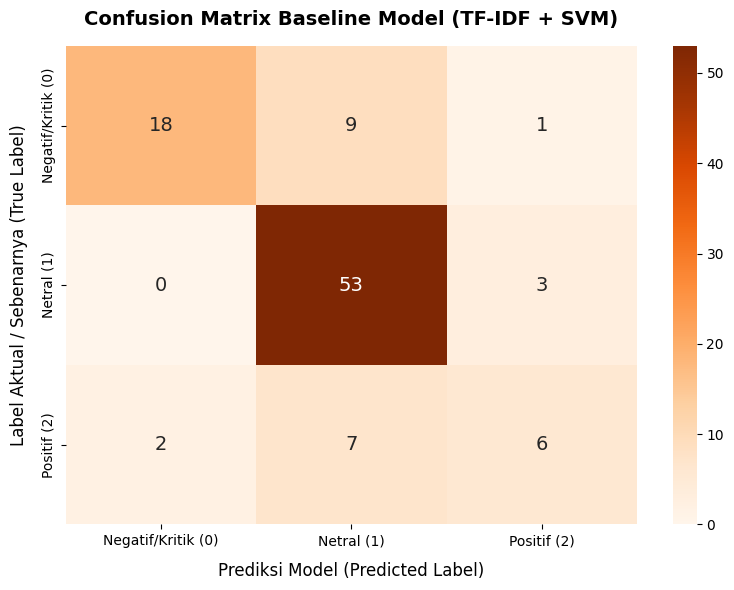

In [ ]:
# 7. Visualisasi Confusion Matrix SVM untuk Perbandingan di Tesis
cm = confusion_matrix(y_test, y_pred)
class_names = ['Negatif/Kritik (0)', 'Netral (1)', 'Positif (2)']
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=class_names,
            yticklabels=class_names,
            cbar=True, annot_kws={"size": 14})

plt.title('Confusion Matrix Baseline Model (TF-IDF + SVM)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Prediksi Model (Predicted Label)', fontsize=12, labelpad=10)
plt.ylabel('Label Aktual / Sebenarnya (True Label)', fontsize=12, labelpad=10)
plt.tight_layout()
plt.savefig('confusion_matrix_svm.png', dpi=300)
plt.show()

###Membandingkan Train dengan Algoritma Random Forest (Ensemble Machine Learning)

Akurasi Model Random Forest (TF-IDF): 0.7475

--- Laporan Klasifikasi Random Forest ---
              precision    recall  f1-score   support

           0       0.86      0.64      0.73        28
           1       0.73      0.95      0.82        56
           2       0.60      0.20      0.30        15

    accuracy                           0.75        99
   macro avg       0.73      0.60      0.62        99
weighted avg       0.74      0.75      0.72        99



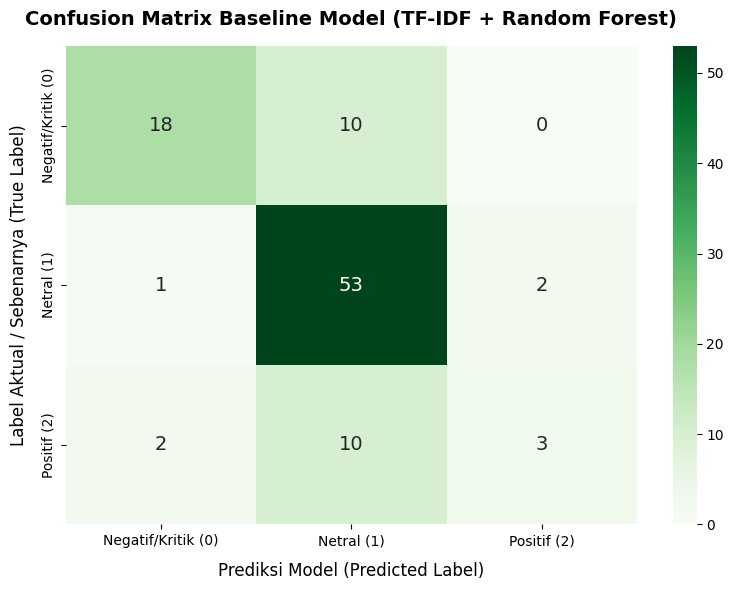

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Pastikan dataset yang bersih dan berlabel sudah dimuat
# (Jika variabel df belum ada, jalankan ulang pemuatan df['cleaned_text'] dan df['label'])
X_text = df['cleaned_text'].values
y = df['label'].values

# 2. Split Data dengan proporsi yang sama persis seperti model sebelumnya
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X_text, y, test_size=0.10, random_state=42, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.1111, random_state=42, stratify=y_train_val
)

# 3. Ekstraksi Fitur Menggunakan TF-IDF Vectorizer
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# 4. Inisialisasi dan Latih Model Random Forest
rf_model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
rf_model.fit(X_train_tfidf, y_train)

# 5. Prediksi pada Test Set
y_pred_rf = rf_model.predict(X_test_tfidf)

# 6. Evaluasi Performa
acc_rf = accuracy_score(y_test, y_pred_rf)
print(f"Akurasi Model Random Forest (TF-IDF): {acc_rf:.4f}\n")
print("--- Laporan Klasifikasi Random Forest ---")
print(classification_report(y_test, y_pred_rf))

# 7. Visualisasi Confusion Matrix Random Forest untuk Perbandingan di Tesis
cm_rf = confusion_matrix(y_test, y_pred_rf)
class_names = ['Negatif/Kritik (0)', 'Netral (1)', 'Positif (2)']

plt.figure(figsize=(8, 6))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens',
            xticklabels=class_names,
            yticklabels=class_names,
            cbar=True, annot_kws={"size": 14})

plt.title('Confusion Matrix Baseline Model (TF-IDF + Random Forest)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Prediksi Model (Predicted Label)', fontsize=12, labelpad=10)
plt.ylabel('Label Aktual / Sebenarnya (True Label)', fontsize=12, labelpad=10)
plt.tight_layout()
plt.savefig('confusion_matrix_rf.png', dpi=300)
plt.show()

###Error Analysis

In [ ]:
import pandas as pd
import torch
from torch.utils.data import DataLoader

# 1. Pastikan test_dataset dan model sudah siap di sesi Colab Anda
# Jalankan inferensi ulang khusus untuk mengumpulkan teks asli, label aktual, dan prediksi model
test_dataset = KarhutlaDataset(test_texts, test_labels, tokenizer, MAX_LEN)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE)

model.eval()
all_preds = []
all_trues = []
all_texts = []

# Ambil teks asli dari test set
for batch_idx, batch in enumerate(test_loader):
    input_ids = batch['input_ids'].to(device)
    attention_mask = batch['attention_mask'].to(device)
    labels = batch['labels'].to(device)

    with torch.no_grad():
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        preds = torch.argmax(outputs.logits, dim=1)

    all_preds.extend(preds.cpu().numpy())
    all_trues.extend(labels.cpu().numpy())

# Petakan indeks ke teks asli test set
# (Pastikan test_texts terdefinisi dari proses split data sebelumnya)
error_records = []
class_mapping = {0: 'Negatif/Kritik', 1: 'Netral', 2: 'Positif'}

for idx, (true_lbl, pred_lbl) in enumerate(zip(all_trues, all_preds)):
    if true_lbl != pred_lbl: # Hanya ambil yang salah prediksi (error)
        error_records.append({
            'Teks Asli': test_texts[idx],
            'Aktual': class_mapping[true_lbl],
            'Prediksi Model': class_mapping[pred_lbl]
        })

# 2. Ubah ke DataFrame untuk ditampilkan
df_errors = pd.DataFrame(error_records)

print(f"Total prediksi yang salah pada Test Set: {len(df_errors)} data dari 99 data total.\n")
print("--- Contoh 5 Kalimat yang Salah Diprediksi (Error Analysis) ---")

# Tampilkan 3 sampai 5 contoh kasus kesalahan
sample_errors = df_errors.head(5)
for i, row in sample_errors.iterrows():
    print(f"Kasus ke-{i+1}:")
    print(f"  - Teks Tuit    : \"{row['Teks Asli']}\"")
    print(f"  - Label Aktual : {row['Aktual']}")
    print(f"  - Prediksi Model: {row['Prediksi Model']}")
    print("-" * 60)

Total prediksi yang salah pada Test Set: 22 data dari 99 data total.

--- Contoh 5 Kalimat yang Salah Diprediksi (Error Analysis) ---
Kasus ke-1:
  - Teks Tuit    : "zaskia adya mecca riyuka bunga lagi jadi relawan di kalimantan update terbaru dari mereka langit di sana tuh masih kuning karena asap karhutla jelas itu bukan filter zaskia kelihatan bantu pemadaman api kebakaran hutan sedangkan riyuka nyindir pemerintah lewat pov"
  - Label Aktual : Positif
  - Prediksi Model: Negatif/Kritik
------------------------------------------------------------
Kasus ke-2:
  - Teks Tuit    : "mahasiswa sthb demonstrasi di dprd jabar soroti isu karhutla dan mbg mahasiswa sekolah tinggi hukum bandung menggelar demonstrasi di depan gedung dprd jabar rabu 28 oktober 2026 mereka menyoroti dua isu besar yakni kebakaran hutan dan lahan karhutla dan program makan"
  - Label Aktual : Negatif/Kritik
  - Prediksi Model: Netral
------------------------------------------------------------
Kasus ke-3:
  - Teks T